## 0. Imports and Path Assignments

In [1]:
import sys
sys.path.append("../helper")
from runtime_memory import *
from visualization import * 
from metrics import * 
from pathlib import Path
import os
import pandas as pd
from glob import glob
from warnings import simplefilter
simplefilter("ignore")

In [2]:
data_dir = Path.cwd().parent / "data" / "runtime_memory"
results_dir = Path.cwd() / "results"
log_dir = Path.cwd() / "logs"
pipelines_dir = data_dir / "pipelines"
fig_dir = Path.cwd() / "figures"
os.makedirs(fig_dir, exist_ok = True)

hue_order=["Xengsort", "ICRG", "bamcmp", "XenofilteR"]

## 1. Alignments

In [3]:
alignments = process_nfcore_traces(data_dir)
alignments["sample"] = alignments["sample"].map(sample_map_short)
alignments["realtime_h"] = alignments["realtime_s"] / 3600
alignments["peak_rss_gb"] = alignments["peak_rss_mb"] / 1000
alignments[alignments["method"] == "Xengsort"]

,sample,replicate,realtime_s,peak_rss_mb,method,stage,realtime_h,peak_rss_gb
24,M1,0,2400.0,47000.0,Xengsort,alignment,0.666667,47.0
25,M1,1,2387.0,46900.0,Xengsort,alignment,0.663056,46.9
26,M1,2,2495.0,46800.0,Xengsort,alignment,0.693056,46.8
27,M2,0,2252.0,41400.0,Xengsort,alignment,0.625556,41.4
28,M2,1,2258.0,41500.0,Xengsort,alignment,0.627222,41.5
29,M2,2,2262.0,41500.0,Xengsort,alignment,0.628333,41.5
30,M4,0,2398.0,41400.0,Xengsort,alignment,0.666111,41.4
31,M4,1,2477.0,41300.0,Xengsort,alignment,0.688056,41.3
32,M4,2,2377.0,41400.0,Xengsort,alignment,0.660278,41.4
33,M3,0,2237.0,41900.0,Xengsort,alignment,0.621389,41.9


In [4]:
alignments['sample_long'] = alignments['sample'].str.replace(r'M(\d+)', r'Mix \1', regex=True)

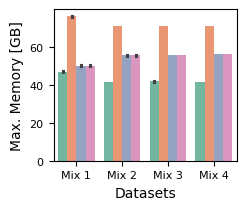

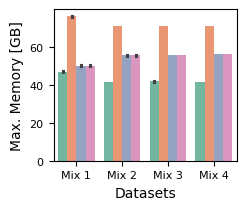

In [5]:
ax, pos = barplot_runmem(alignments, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_alignment_maxmemory.pdf")
ax, pos = barplot_runmem(alignments, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_alignment_maxmemory.png")


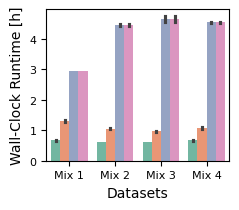

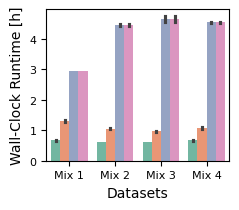

In [6]:
ax, pos = barplot_runmem(alignments, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue = "method", figsize=mm_to_inches((60, 50)), legend=False, hue_order = hue_order, errorbar = "sd",
               save=True, fig_dir=fig_dir, file_name="barplot_alignment_runtime.pdf", xlabel = "Datasets")

ax, pos = barplot_runmem(alignments, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue = "method", figsize=mm_to_inches((60, 50)), legend=False, hue_order = hue_order, errorbar = "sd",
               save=True, fig_dir=fig_dir, file_name="barplot_alignment_runtime.png", xlabel = "Datasets")

## 2. Read sortings

In [7]:
xengsort = parse_lsf_logs(log_dir / "logs_newindex", method="xengsort", pattern="xengsort_*.out")
xengsort["sample"] = xengsort["sample"].map(sample_map_short1)
xengsort

,sample,replicate,realtime_s,peak_rss_mb,method
0,M1,0,648.0,41451.0,xengsort
1,M1,1,651.0,41427.0,xengsort
2,M1,2,645.0,41414.0,xengsort
3,M2,0,520.0,41503.0,xengsort
4,M2,1,522.0,41495.0,xengsort
5,M2,2,524.0,41498.0,xengsort
6,M3,0,522.0,41501.0,xengsort
7,M3,1,526.0,41489.0,xengsort
8,M3,2,527.0,41489.0,xengsort
9,M4,0,726.0,41512.0,xengsort


In [8]:
xengsort = parse_lsf_logs(log_dir / "logs_newindex", method="xengsort", pattern="xengsort_*.out")
xengsort["sample"] = xengsort["sample"].map(sample_map_short1)

bamcmp   = parse_lsf_logs(log_dir, method="bamcmp",   pattern="bamcmp_*.out")
bamcmp["sample"] = bamcmp["sample"].map(sample_map_short1)

xenofilter = parse_lsf_logs(log_dir, method="xenofilter", pattern="xenofilter_*.out")
xenofilter["sample"] = xenofilter["sample"].str.strip().map(sample_map_short1)


In [9]:
sortings = pd.concat([xengsort, bamcmp, xenofilter], ignore_index = True) 
sortings["realtime_h"] = sortings["realtime_s"] / 3600
sortings["peak_rss_gb"] = sortings["peak_rss_mb"] / 1000 # SI units 
sortings["method"] = sortings["method"].map(method_map)
sortings["stage"] = "sorting"
sortings['sample_long'] = sortings['sample'].str.replace(r'M(\d+)', r'Mix \1', regex=True)

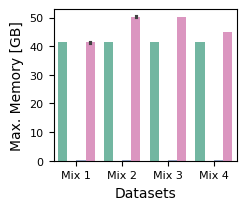

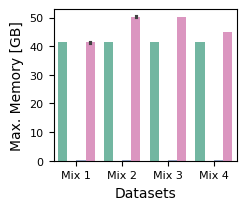

In [10]:
ax, pos = barplot_runmem(sortings, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd",xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_maxmemory.pdf")
ax, pos = barplot_runmem(sortings, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd",xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_maxmemory.png");


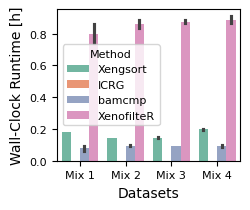

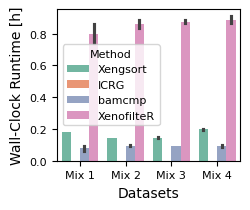

In [11]:
ax, pos = barplot_runmem(sortings, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_runtime.pdf")

ax, pos = barplot_runmem(sortings, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_runtime.png")


## 3. Alignment  + Sorting

In [12]:
concat = pd.concat([alignments, sortings], ignore_index = True)

In [13]:
final_df = (
    concat
    .groupby(["sample_long", "method", "replicate"], as_index=False)
    .agg(realtime_s=("realtime_s", "sum"), peak_rss_mb=("peak_rss_mb", "max"))
)
final_df["realtime_h"]  = final_df["realtime_s"] / 3600
final_df["peak_rss_gb"] = final_df["peak_rss_mb"] / 1000


In [45]:
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path


def barplot_runmem(
    df, x="sample", y="peak_rss_gb", hue="method",
    xlabel=None, ylabel=None, figsize=None, errorbar=None, legend=True,
    palette=None, ylabel_fs=10, xlabel_fs=10, xtick_fs=8, ytick_fs=8,
    hue_order=None, xtick_rotation=0, bar_alpha=0.4, bar_lw=1.5,
    margins=(0.22, 0.20, 0.97, 0.97),
    save=False, fig_dir="./", file_name="barplot.png",
    horizontal=False, reverse_order=False
):
    fig, ax = plt.subplots(figsize=figsize)

    if palette is None:
        palette = sns.color_palette("Set2")
    if hue_order is None:
        hue_order = list(df[hue].dropna().unique())

    sample_order = sorted(df[x].unique(), reverse=reverse_order)

    if horizontal:
        plot_x, plot_y = y, x
        xlabel = xlabel or y
        ylabel = ylabel or x
    else:
        plot_x, plot_y = x, y
        xlabel = xlabel or x
        ylabel = ylabel or y

    sns.barplot(
        data=df, x=plot_x, y=plot_y, hue=hue, errorbar=errorbar,
        legend=legend, palette=palette, ax=ax,
        order=sample_order, hue_order=hue_order,
    )

    for p in ax.patches:
        r, g, b, _ = p.get_facecolor()
        p.set_edgecolor((r, g, b, 1))
        p.set_facecolor((r, g, b, bar_alpha))
        p.set_linewidth(bar_lw)

    ax.set_xlabel(xlabel, fontsize=xlabel_fs)
    ax.set_ylabel(ylabel, fontsize=ylabel_fs)
    ax.tick_params(axis="x", labelsize=xtick_fs)
    ax.tick_params(axis="y", labelsize=ytick_fs)

    if xtick_rotation != 0 and not horizontal:
        ax.tick_params(axis="x", rotation=xtick_rotation)
        plt.setp(ax.get_xticklabels(), ha="right")

    if legend:
        ax.legend(title="Method", fontsize=8, title_fontsize=8)
    elif ax.get_legend() is not None:
        ax.get_legend().remove()

    left, bottom, right, top = margins
    fig.subplots_adjust(left=left, bottom=bottom, right=right, top=top)

    if save:
        fig.savefig(Path(fig_dir) / file_name, dpi=300, pad_inches=0)

    return ax, ax.get_position()

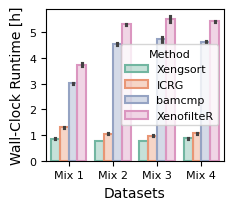

In [46]:
ax, pos = barplot_runmem(final_df, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_final_runtime.pdf")



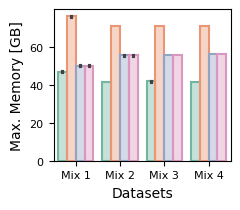

In [47]:
ax, pos = barplot_runmem(final_df, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_final_maxmemory.pdf")



In [50]:
summary_df 

,method,realtime_s,peak_rss_mb,realtime_h,peak_rss_gb
0,ICRG,3957.833333,72150.000000,1.099398,72.150000
1,Xengsort,2940.083333,42911.083333,0.816690,42.911083
2,XenofilteR,17998.750000,54366.666667,4.999653,54.366667
3,bamcmp,15243.416667,54366.666667,4.234282,54.366667


In [49]:
summary_df = (
    final_df
    .groupby("method", as_index=False)
    .agg(realtime_s=("realtime_s", "mean"), peak_rss_mb=("peak_rss_mb", "mean"))
)
summary_df["realtime_h"]  = summary_df["realtime_s"] / 3600
summary_df["peak_rss_gb"] = summary_df["peak_rss_mb"] / 1000


## Save dataframes

In [27]:
sortings.to_csv(results_dir / "sortings.csv")
alignments.to_csv(results_dir / "alignments.csv")
final_df.to_csv(results_dir / "final.csv")
summary_df.to_csv(results_dir /"summary.csv")